### HOMO-LUMO gap energy modeling
BERN02 Challenge Project v0.1.1

Preston Stover and Luobin Wang - Oct 2026

In [1]:
# %% Cell 1 --------------------------------------------------------------------------
# 1 imports and settings
import os
import time
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
# chem
from scipy import stats
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors, rdFingerprintGenerator
# modeling
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import shap

# CONSTANTS:
# file structure
GW_FILE = Path("data/gw/db_new_qm9_gw.csv")
XYZ_DIR = Path("data/qm9/dsgdb9nsd.xyz")
UNCHARACTERIZED_LIST = Path("data/qm9/uncharacterized.txt")
RESULTS_DIR = Path("results/gap_gw")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
# model
HARTREE_TO_EV = 27.211386
SEED = 42
TEST_FRACTION = 0.20
DROP_VARIABLES = ["n_small_rings", "n_F", "molar_refractivity", "n_heavy_atoms", "n_O", "tpsa", "n_nitrile"]
# Morgan fingerprint
FP_RADIUS = 2       # Morgan radius 2: atom environments up to 2 bonds away
FP_VOCAB_SIZE = 256     # keep the x most frequent training substructures
# stats
LEARNING_CURVE_SIZES = [1000, 2000, 4000, 8000, 16000, 32000, 64000]    # for plot
N_SHAP = 2000   # test molecules explained with SHAP
N_GALLERY = 8                # substructures drawn in the gallery
RUN_FINAL_CV = True          # step 10 takes most of the run time; set False while developing
# figures
MODEL_NAMES = {"A": "A: chemistry variables", "B": "B: Morgan counts", "C": "C: combined", "D": "D: Ridge (C)"}
MODEL_COLORS = {"baseline": "#8c8c8c", "A": "#0072B2", "B": "#E69F00", "C": "#009E73", "D": "#CC79A7"}

# debugging
RDLogger.DisableLog("rdApp.*")   # hide RDKit warning
# runtime notice
START = time.perf_counter()
def notice(message):
    elapsed = time.perf_counter() - START
    print(f"[{int(elapsed // 60):3d} min {elapsed % 60:4.1f} s] {message}", flush=True)

/Users/cookcook/Documents/LundUniversity/BERN02/challenge/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Data import and Variable Generation

In [2]:
# %% Cell 2 --------------------------------------------------------------------------
# 2 read index, gap, and SMILES from QM9 .xyz files to pandas dataframe
def read_xyz(path):
    """Line 1 = number of atoms n; line 2 = properties; line n+4 = SMILES."""
    lines = path.read_text().splitlines()
    n_atoms = int(lines[0])
    props = lines[1].replace("*^", "e").split()       # "1.2*^-6" -> "1.2e-6"
    return {"index": int(props[1]),                   # props[9] = gap in Hartree
            "gap_eV": float(props[9]) * HARTREE_TO_EV,
            "smiles": lines[n_atoms + 3].split()[1]}  # SMILES after DFT relaxation

xyz_files = sorted(XYZ_DIR.glob("*.xyz"))
notice(f"Cell 2: reading {len(xyz_files)} .xyz files") # 133885
qm9 = pd.DataFrame([read_xyz(p) for p in xyz_files])
notice("Cell 2 finished")

#%% Cell 2.5 --------------------------------------------------------------------------
# import gw occ_scf / vir_scf values to use as HOMO-LUMO gap
gw = pd.read_csv(GW_FILE)
gw_table = pd.DataFrame({
    "index": gw["Unnamed: 0"].astype(int),
    "gw_gap_eV": gw["vir_scf"] - gw["occ_scf"], # GW gap = LUMO - HOMO in eV
})

n_before = len(qm9)
qm9 = qm9.merge(gw_table, on="index", how="inner", validate="one_to_one") # adds GW energies to a new column in qm9 dataframe
qm9 = qm9.dropna(subset=["gw_gap_eV"]) # only keeps molecules with GW values (133,885 in vs 130,219 out)
notice(f"GW gaps attached: {n_before} -> {len(qm9)} molecules")
print(qm9[["gap_eV", "gw_gap_eV"]].describe().round(2))
print("correlation B3LYP vs GW gap:", round(qm9["gap_eV"].corr(qm9["gw_gap_eV"]), 3))

# %% Cell 3 --------------------------------------------------------------------------
# 3 qm9 data check
n_read = len(qm9)
bad_index = {int(line.split()[0]) for line in UNCHARACTERIZED_LIST.read_text().splitlines()
             if line.split() and line.split()[0].isdigit()}
qm9 = qm9[~qm9["index"].isin(bad_index)]    # remove molecules with failed geometry check
n_characterized = len(qm9)

qm9["mol"] = [Chem.MolFromSmiles(s) for s in qm9["smiles"]]     # readable SMILES sequences only
qm9 = qm9[qm9["mol"].notna()]
n_parsed = len(qm9)

qm9["canonical"] = [Chem.MolToSmiles(m) for m in qm9["mol"]]    # one row per structure
molecules = (qm9.groupby("canonical", sort=False)
                .agg(index=("index", "first"), gap_eV=("gw_gap_eV", "mean"), # CHANGED TO GW HERE
                     mol=("mol", "first"), n_copies=("index", "size"))
                .reset_index())
y = molecules["gap_eV"].to_numpy()
#del qm9     # frees memory of second copy of every qm9 molecule
notice(f"Cell 3 finished: read {n_read} -> characterized {n_characterized} -> parsed {n_parsed} "
       f"-> unique structures {len(molecules)}")
print("target mean:", round(y.mean(), 2), "eV")   # GW ~10.7, B3LYP ~6.9

# %% Cell 4 --------------------------------------------------------------------------
# 4 generate variables from SMILES
# all variables to extract from SMILES data:
SMILES_VARS = {
    "n_conjugated_bonds": "-", "n_aromatic_rings": "-", "frac_sp3_carbon": "+",
    "n_pi_electrons": "-", "n_carbonyl": "-",
    "n_N": "-", "n_O": "-", "n_F": "?", "n_small_rings": "-", "n_rings": "?",
    "n_heavy_atoms": "?", "molar_refractivity": "?", "tpsa": "?",
    "max_partial_charge": "?", "min_partial_charge": "?",}
PI_ELECTRONS = {Chem.BondType.DOUBLE: 2, Chem.BondType.TRIPLE: 4, Chem.BondType.AROMATIC: 1}

def chem_vars(mol):
    # uses RDKit and other methods to extract SMILES_VARS from input molecule
    # TODO: add line to measure longest conjugated chain of pi bonds
    bonds = list(mol.GetBonds())
    atoms = [a.GetSymbol() for a in mol.GetAtoms()]
    ring_sizes = [len(r) for r in mol.GetRingInfo().AtomRings()]
    return {
        "n_conjugated_bonds": sum(b.GetIsConjugated() for b in bonds),
        "n_aromatic_rings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "frac_sp3_carbon": rdMolDescriptors.CalcFractionCSP3(mol),
        "n_pi_electrons": sum(PI_ELECTRONS.get(b.GetBondType(), 0) for b in bonds),
        "n_carbonyl": Descriptors.fr_C_O(mol),
        "n_nitrile": Descriptors.fr_nitrile(mol),
        "n_N": atoms.count("N"), "n_O": atoms.count("O"), "n_F": atoms.count("F"),
        "n_small_rings": sum(size <= 4 for size in ring_sizes),
        "n_rings": len(ring_sizes),
        "n_heavy_atoms": mol.GetNumHeavyAtoms(),
        "molar_refractivity": Descriptors.MolMR(mol),
        "tpsa": Descriptors.TPSA(mol),
        "max_partial_charge": Descriptors.MaxPartialCharge(mol),
        "min_partial_charge": Descriptors.MinPartialCharge(mol),}

X_chem_all = pd.DataFrame([chem_vars(m) for m in molecules["mol"]]).astype(float)
notice("Cell 4 finished: SMILES-based vars generated")

# %% Cell 5 --------------------------------------------------------------------------
# 5 generate Morgan fingerprint variables with RDKit
"""Morgan algorithm describes all atoms' neighbourhood (bonds within Morgan radius) and turns 
that neighbourhood into an integer id. "Unfolded" = keep the real ids instead of hashing them 
into a fixed number of columns, so two different substructures can never share a column 
(no "bit collisions"). "Count" = how many times each substructure occurs"""

morgan = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS)
fp_dicts = [morgan.GetSparseCountFingerprint(m).GetNonzeroElements() for m in molecules["mol"]]
notice(f"Cell 5: {len({k for d in fp_dicts for k in d})} unique substructures in the dataset")

def fp_vocab(train_positions):
    # rank substructures by how many training set molecules contain them and keep the 
    # FP_VOCAB_SIZE most common
    frequency = Counter(sub_id for i in train_positions for sub_id in fp_dicts[i])
    ranked = sorted(frequency.items(), key=lambda kv: (-kv[1], kv[0]))  # ties: smaller id first
    return [sub_id for sub_id, _ in ranked[:FP_VOCAB_SIZE]]

def fp_table(vocabulary):
    # fp count matrix (molecules x vocabulary) with one named column per substructure.
    column_of = {sub_id: j for j, sub_id in enumerate(vocabulary)}
    counts = np.zeros((len(fp_dicts), len(vocabulary)), dtype=np.float32)
    for i, d in enumerate(fp_dicts):
        for sub_id, count in d.items():
            j = column_of.get(sub_id)          # None if this substructure is not a column
            if j is not None:
                counts[i, j] = count
    return pd.DataFrame(counts, columns=[f"fp_{sub_id}" for sub_id in vocabulary])

[  0 min  0.6 s] Cell 2: reading 133885 .xyz files
[  0 min  4.0 s] Cell 2 finished
[  0 min  4.2 s] GW gaps attached: 133885 -> 133885 molecules
          gap_eV  gw_gap_eV
count  133885.00  133885.00
mean        6.83      10.64
std         1.29       0.90
min         0.67       4.40
25%         5.89      10.16
50%         6.79      10.76
75%         7.84      11.21
max        16.93      18.55
correlation B3LYP vs GW gap: 0.591
[  0 min  8.0 s] Cell 3 finished: read 133885 -> characterized 130831 -> parsed 130219 -> unique structures 130085
target mean: 10.66 eV
[  0 min 21.7 s] Cell 4 finished: SMILES-based vars generated
[  0 min 22.5 s] Cell 5: 182962 unique substructures in the dataset


          gap_eV  gw_gap_eV
count  130219.00  130219.00
mean        6.87      10.66
std         1.27       0.87
min         2.14       4.43
25%         5.92      10.19
50%         6.82      10.77
75%         7.88      11.22
max        16.93      18.55
Spearman: 0.52
GW HOMO vs PBE HOMO: 0.894
GW LUMO vs PBE LUMO: 0.782
       occ_scf_err  vir_scf_err  vir_scf_r2
count     133885.0     133885.0  133885.000
mean           0.0          0.0       1.000
std            0.0          0.0       0.016
min            0.0          0.0       0.000
25%            0.0          0.0       1.000
50%            0.0          0.0       1.000
75%            0.0          0.0       1.000
max            0.0          0.0       1.000


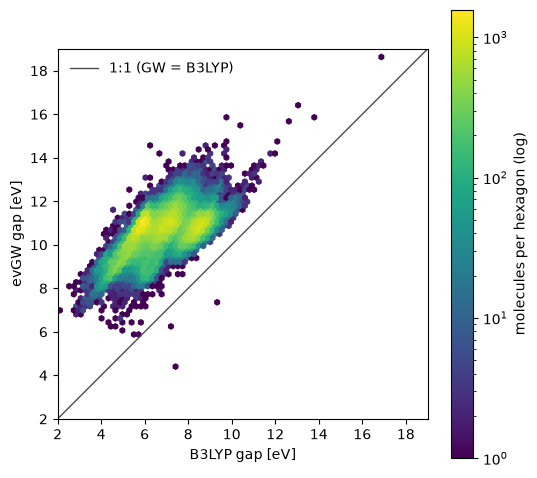

In [12]:
# diagnostic of gw data
print(qm9[["gap_eV", "gw_gap_eV"]].describe().round(2))
print("Spearman:", round(qm9["gap_eV"].corr(qm9["gw_gap_eV"], method="spearman"), 3))

# which half of the gap disagrees? (GW file only, no merge needed)
print("GW HOMO vs PBE HOMO:", round(gw["occ_scf"].corr(gw["homo"]), 3))
print("GW LUMO vs PBE LUMO:", round(gw["vir_scf"].corr(gw["lumo"]), 3))
print(gw[["occ_scf_err", "vir_scf_err", "vir_scf_r2"]].describe().round(3))

low = np.floor(min(qm9["gap_eV"].min(), qm9["gw_gap_eV"].min()))
high = np.ceil(max(qm9["gap_eV"].max(), qm9["gw_gap_eV"].max()))
lims = [low, high]
ticks = np.arange(low, high + 1, 2)          # a tick every 2 eV

fig, ax = plt.subplots(figsize=(5.5, 5))
hb = ax.hexbin(qm9["gap_eV"], qm9["gw_gap_eV"], gridsize=80, mincnt=1, bins="log",
               extent=(*lims, *lims))
ax.plot(lims, lims, color="0.3", linewidth=1, label="1:1 (GW = B3LYP)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_aspect("equal")
ax.set_xlabel("B3LYP gap [eV]")
ax.set_ylabel("evGW gap [eV]")
ax.legend(loc="upper left", frameon=False)
fig.colorbar(hb, label="molecules per hexagon (log)")
fig.tight_layout()

### Train and Test

In [4]:
# %% Cell 6 --------------------------------------------------------------------------
# 6 train/test split, variable correlation, drop vars
positions = np.arange(len(molecules))      # train/test split based on these row numbers of all sorted mols
train_pos, test_pos = train_test_split(positions, test_size=TEST_FRACTION, random_state=SEED)
print(f"Training: {len(train_pos)}   Test: {len(test_pos)}")

# training data variable correlation
rho = X_chem_all.iloc[train_pos].corr(method="spearman")
pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1))
            .stack().dropna().reset_index())
pairs.columns = ["variable_1", "variable_2", "rho"]
pairs = pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index)
print("Spearman rho correlation table:")
print(pairs.head(10).round(2).to_string(index=False))
# remove dropped variables
features = [c for c in X_chem_all.columns if c not in DROP_VARIABLES]
X_chem = X_chem_all[features]
notice(f"Cell 6 finished: chem variables used: {len(features)}; dropped: {DROP_VARIABLES or 'none'}")

# %% Cell 7 --------------------------------------------------------------------------
# 7 regression models
def model_inputs(vocabulary):
    # Input variable arrangements for each model.
    fp = fp_table(vocabulary)
    return {"A": X_chem, "B": fp, "C": pd.concat([X_chem, fp], axis=1)}


def fit_and_test(train, test, which=("A", "B", "C")):
    # Build vocab from train, fit models, test
    vocabulary = fp_vocab(train)
    inputs = model_inputs(vocabulary)
    results = {"baseline": {"mae": mean_absolute_error(y[test], np.full(len(test), y[train].mean()))}}
    for name in which:
        model = HistGradientBoostingRegressor(random_state=SEED) # regression model chosen
        model.fit(inputs[name].iloc[train], y[train])
        pred = model.predict(inputs[name].iloc[test])
        results[name] = {"model": model, "pred": pred, "mae": mean_absolute_error(y[test], pred)}
    return results, inputs

main, main_inputs = fit_and_test(train_pos, test_pos) # run regressions
notice("Cell 7 finished: regression models done")

Training: 104068   Test: 26017
Spearman rho correlation table:
        variable_1         variable_2   rho
   frac_sp3_carbon     n_pi_electrons -0.89
     n_small_rings            n_rings  0.79
n_conjugated_bonds    frac_sp3_carbon -0.72
n_conjugated_bonds   n_aromatic_rings  0.69
n_conjugated_bonds     n_pi_electrons  0.64
   frac_sp3_carbon      n_small_rings  0.63
n_conjugated_bonds max_partial_charge  0.62
              tpsa max_partial_charge  0.61
               n_N               tpsa  0.58
  n_aromatic_rings    frac_sp3_carbon -0.57
[  0 min 22.7 s] Cell 6 finished: chem variables used: 9; dropped: ['n_small_rings', 'n_F', 'molar_refractivity', 'n_heavy_atoms', 'n_O', 'tpsa', 'n_nitrile']
[  0 min 30.6 s] Cell 7 finished: regression models done


In [5]:
# %% Cell 7 plus --------------------------------------------------------------------------
# Luobin's model: Ridge Regression
def Luobin_model (train, test, which = ('A','B','C')):
    vocabulary = fp_vocab(train)
    inputs = model_inputs(vocabulary)
    results = {}
    for name in which:
        model = make_pipeline(
            SimpleImputer(strategy="median"),     # linear model cannot handle NaN
            StandardScaler(),                     # penalty must see all variables on one scale
            RidgeCV(alphas=np.logspace(-3, 3, 13), cv=5))  # alpha chosen by 5-fold CV, training data only
        X = inputs[name].astype("float64")          # ridge solves normal equations: needs double precision
        model.fit(X.iloc[train], y[train])
        pred = model.predict(X.iloc[test])
        results[name] = {"model": model, "pred": pred,
                         "mae": mean_absolute_error(y[test], pred),
                         "alpha": model[-1].alpha_}
    return results

ridge = Luobin_model(train_pos, test_pos)

print({k: (round(v["mae"], 3), v["alpha"]) for k, v in ridge.items()})
coef_A = pd.Series(ridge["A"]["model"][-1].coef_, index=main_inputs["A"].columns)
coef_C = pd.Series(ridge["C"]["model"][-1].coef_, index=main_inputs["C"].columns)
print(coef_A.sort_values(key=np.abs, ascending=False).round(3))
print(main_inputs["C"].dtypes.value_counts())
print(coef_C.sort_values(key=np.abs, ascending=False).round(3))
print(main_inputs["C"].dtypes.value_counts())

{'A': (0.466, np.float64(3.1622776601683795)), 'B': (0.35, np.float64(10.0)), 'C': (0.337, np.float64(10.0))}
n_conjugated_bonds   -0.658
frac_sp3_carbon       0.461
n_pi_electrons        0.351
max_partial_charge    0.339
n_rings              -0.212
n_aromatic_rings      0.114
n_carbonyl           -0.079
min_partial_charge   -0.020
n_N                  -0.020
dtype: float64
float32    256
float64      9
Name: count, dtype: int64
fp_3217380708   -0.551
fp_864942730    -0.491
fp_2976033787   -0.409
fp_3218693969   -0.379
fp_847433064     0.377
                 ...  
fp_1823304278    0.000
fp_1100037548   -0.000
fp_3616095757   -0.000
fp_942105187    -0.000
fp_1676823234    0.000
Length: 265, dtype: float64
float32    256
float64      9
Name: count, dtype: int64


### Figures and Statistics

                        MAE (eV)  RMSE (eV)     R2  RMSE/MAE
baseline (mean)            0.671      0.874 -0.000     1.304
A: chemistry variables     0.330      0.438  0.750     1.326
B: Morgan counts           0.311      0.417  0.773     1.338
C: combined                0.284      0.381  0.810     1.342
D: Ridge (C)               0.337      0.451  0.734     1.337
[  0 min 39.9 s] Step 6: drawing parity plots (Figure 4)
[  0 min 40.1 s] Cell 8 finished: saved parity_A_vs_C.png
                    mean |SHAP| (eV) expected observed
n_conjugated_bonds             0.298        -        -
max_partial_charge             0.103        ?        +
n_rings                        0.094        ?        -
min_partial_charge             0.043        ?        -
n_aromatic_rings               0.029        -        +
n_N                            0.024        -        -
n_carbonyl                     0.019        -        -
n_pi_electrons                 0.014        -        +
frac_sp3_carbon         

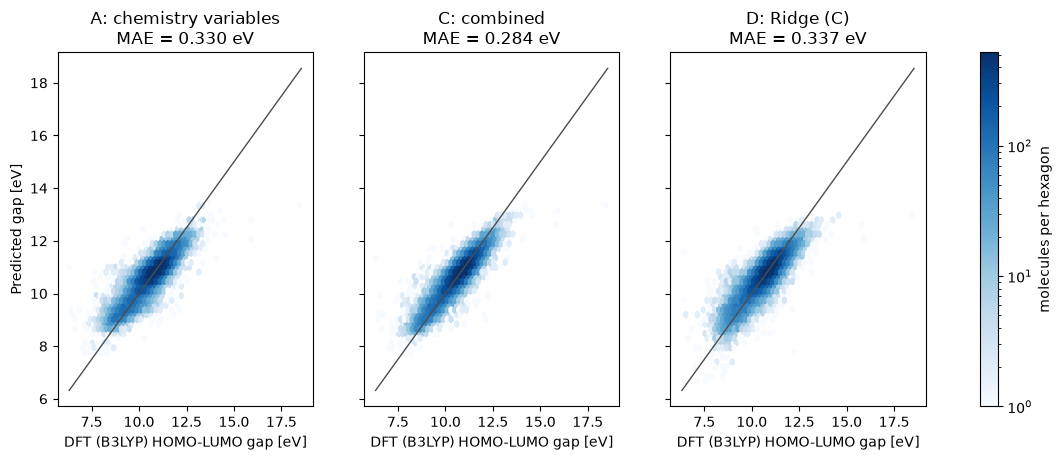

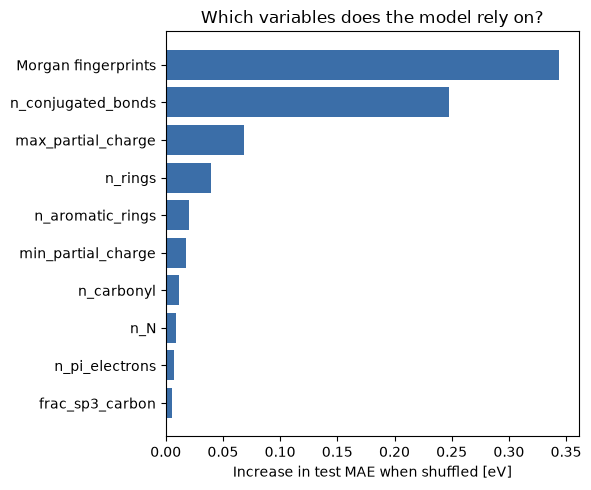

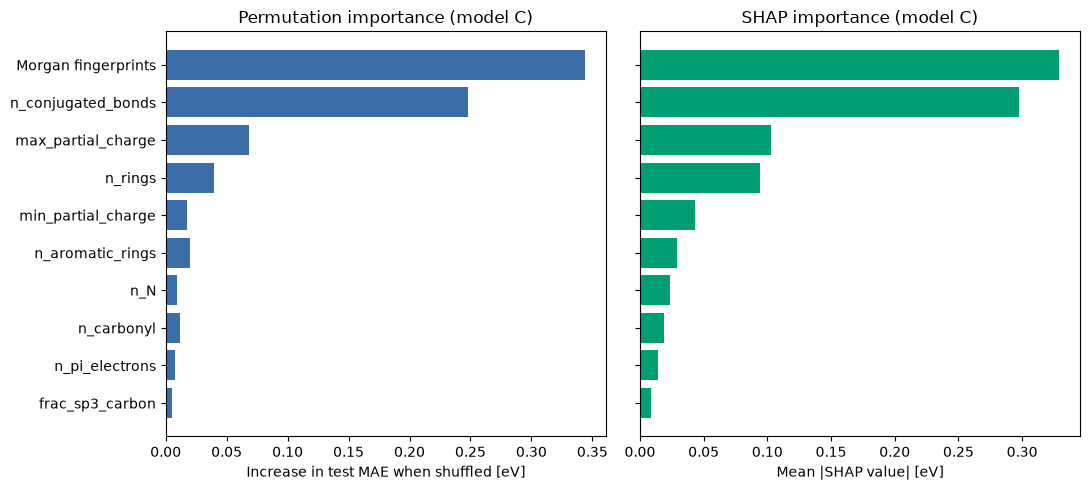

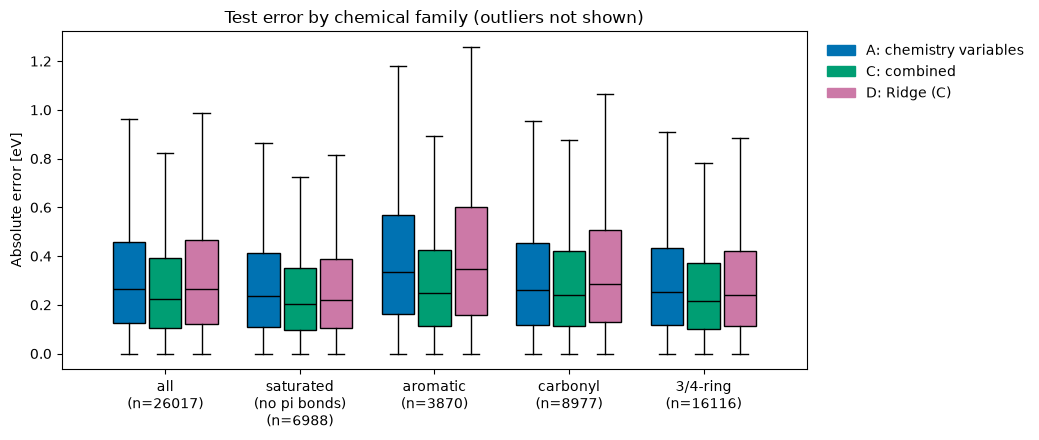

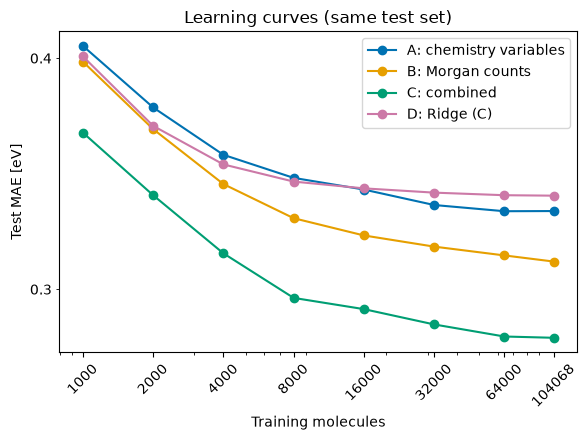

In [6]:
# %% Cell 8 --------------------------------------------------------------------------
# 8 score models
# calculate stats table
y_test = y[test_pos]
baseline_pred = np.full(len(test_pos), y[train_pos].mean())
rows = {"baseline (mean)": baseline_pred}
main["D"] = ridge["C"]      # same keys as the tree models, so D works in every loop below
rows.update({MODEL_NAMES[k]: main[k]["pred"] for k in "ABCD"}) 
scores = pd.DataFrame({name: [mean_absolute_error(y_test, p), root_mean_squared_error(y_test, p),
                              r2_score(y_test, p)] for name, p in rows.items()},
                      index=["MAE (eV)", "RMSE (eV)", "R2"]).T
scores["RMSE/MAE"] = scores["RMSE (eV)"] / scores["MAE (eV)"]
print(scores.round(3))

# Figure: A and C models side by sidee
notice("Step 6: drawing parity plots (Figure 4)")
lims = [y_test.min(), y_test.max()]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, key in zip(axes, ["A", "C", "D"]):
    hb = ax.hexbin(y_test, main[key]["pred"], gridsize=60, mincnt=1, bins="log",
                   cmap="Blues", extent=(*lims, *lims), vmin=1, vmax=len(y_test) / 50)
    ax.plot(lims, lims, color="0.3", linewidth=1)
    ax.set_title(f"{MODEL_NAMES[key]}\nMAE = {main[key]['mae']:.3f} eV")
    ax.set_xlabel("DFT (B3LYP) HOMO-LUMO gap [eV]")
axes[0].set_ylabel("Predicted gap [eV]")
fig.colorbar(hb, ax=axes, label="molecules per hexagon")
fig.savefig(RESULTS_DIR / "parity_A_C_D.png", dpi=200, bbox_inches="tight")
notice("Cell 8 finished: saved parity_A_vs_C.png")

# %% Cell 9 --------------------------------------------------------------------------
# 9 variable analyses and figures

# SHAP splits each prediction into one contribution per input (in eV) that add up to
# (prediction - average prediction).
model_C = main["C"]["model"]
X_C = main_inputs["C"]
shap_rows = np.random.default_rng(SEED).choice(test_pos, size=min(N_SHAP, len(test_pos)),replace=False)
X_shap = X_C.iloc[shap_rows]
shap_values = shap.TreeExplainer(model_C).shap_values(X_shap)   # molecules x inputs
shap_df = pd.DataFrame(shap_values, columns=X_C.columns, index=X_shap.index)
mean_abs = shap_df.abs().mean().sort_values(ascending=False)    # overall importance

# permutation importance: shuffle 1 variable in the test set and measure how much the MAE grows.
# model C (chemistry vars only) is used so the index aligns with features.
model_C = main["C"]["model"]
X_C_test = main_inputs["C"].iloc[test_pos]
fp_columns = [c for c in X_C_test.columns if c.startswith("fp_")] # combine fp vars
groups = {name: [name] for name in features}    # each chemistry variable on its own
groups["Morgan fingerprints"] = fp_columns  # all fingerprint columns as one block
# calculate mae, importance for each var left out:
rng = np.random.default_rng(SEED)
base_mae = mean_absolute_error(y_test, model_C.predict(X_C_test))
importance = {}
for group_name, columns in groups.items():
    increases = []
    for _ in range(5):      # 5 repeats
        shuffled = X_C_test.copy()
        order = rng.permutation(len(shuffled)) # random variable selected
        shuffled[columns] = shuffled[columns].to_numpy()[order]
        increases.append(mean_absolute_error(y_test, model_C.predict(shuffled)) - base_mae)
    importance[group_name] = np.mean(increases)
importance = pd.Series(importance)
# shap grouping
shap_groups = shap_df[features].copy()
shap_groups["Morgan fingerprints"] = shap_df[fp_columns].sum(axis=1)   # total fingerprint effect per molecule
shap_importance = shap_groups.abs().mean()  # average size of effect in eV

# permutation importance bar chart (mirrors qm9_gap_culled figure)
fig, ax = plt.subplots(figsize=(6, 5))
ordered = importance.sort_values()
ax.barh(ordered.index, ordered.values, color="#3b6ea8")
ax.set_xlabel("Increase in test MAE when shuffled [eV]")
ax.set_title("Which variables does the model rely on?")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "permutation_importance_cull.png", dpi=200)

# shap and permutation importance shared plot
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
order = shap_importance.sort_values().index
axes[0].barh(order, importance[order], color="#3b6ea8")
axes[0].set_xlabel("Increase in test MAE when shuffled [eV]")
axes[0].set_title("Permutation importance (model C)")
axes[1].barh(order, shap_importance[order], color="#009E73")
axes[1].set_xlabel("Mean |SHAP value| [eV]")
axes[1].set_title("SHAP importance (model C)")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "importance_permutation_vs_shap.png", dpi=200)

# SMILES-based variables' observed direction = sign of the rank correlation between a
# variable's value and its SHAP contribution. Only meaningful for important variables.
def observed_direction(name):
    if X_shap[name].nunique() < 2:
        return "too rare"
    if shap_df[name].nunique() < 2:     # model never splits on this variable
        return "not used"
    return "+" if stats.spearmanr(X_shap[name], shap_df[name]).statistic > 0 else "-"
direction = pd.DataFrame({
    "mean |SHAP| (eV)": mean_abs[features].round(3),
    "expected": [SMILES_VARS.get(f, "?") for f in features],
    "observed": [observed_direction(f) for f in features],
}).sort_values("mean |SHAP| (eV)", ascending=False)
print(direction.to_string())

# fp substructures
'''Substructure gallery: most important Morgan fingerprints, each drawn
in an example molecule with fp atom highlighted, labelled with the average SHAP
value when present (negative = lowers the predicted gap).'''
fp_cols = [c for c in mean_abs.index if c.startswith("fp_")][:N_GALLERY]
gallery_mols, gallery_atoms, gallery_labels = [], [], []
for col in fp_cols:
    sub_id = int(col[3:])
    present = X_shap[col] > 0
    effect = shap_df.loc[present, col].mean()
    n_containing = int((X_C[col] > 0).sum())
    example = molecules["mol"].iloc[X_shap.index[present][0]]
    info = rdFingerprintGenerator.AdditionalOutput()
    info.AllocateBitInfoMap()
    morgan.GetSparseCountFingerprint(example, additionalOutput=info)
    center, radius = info.GetBitInfoMap()[sub_id][0]           # where the substructure sits
    bond_ids = Chem.FindAtomEnvironmentOfRadiusN(example, radius, center)
    atoms = {center} | {a for b in bond_ids for a in (example.GetBondWithIdx(b).GetBeginAtomIdx(),
                                                      example.GetBondWithIdx(b).GetEndAtomIdx())}
    gallery_mols.append(example)
    gallery_atoms.append(sorted(atoms))
    gallery_labels.append(f"{effect:+.2f} eV | in {n_containing} molecules")
# had to rewrite the image saver since RDKit draws differently in .ipynb vs .py
png = Draw.MolsToGridImage(gallery_mols, molsPerRow=4, subImgSize=(260, 200),
                           legends=gallery_labels, highlightAtomLists=gallery_atoms,
                           returnPNG=True)
png = getattr(png, "data", png)      # Jupyter wraps the PNG; .data holds the raw bytes
(RESULTS_DIR / "substructure_gallery.png").write_bytes(png)

# chemical family errors
test_chem = X_chem_all.iloc[test_pos].reset_index(drop=True)
families = {
    "all": np.ones(len(test_pos), dtype=bool),
    "saturated\n(no pi bonds)": (test_chem["n_pi_electrons"] == 0).to_numpy(),
    "aromatic": (test_chem["n_aromatic_rings"] > 0).to_numpy(),
    "carbonyl": (test_chem["n_carbonyl"] > 0).to_numpy(),
    "3/4-ring": (test_chem["n_small_rings"] > 0).to_numpy(),}
abs_err = {k: np.abs(main[k]["pred"] - y_test) for k in "ACD"}
fig, ax = plt.subplots(figsize=(10.5, 4.5))
for i, (fam, mask) in enumerate(families.items()):
    for shift, k in [(-0.27, "A"), (0.0, "C"),(0.27,"D")]:
        box = ax.boxplot(abs_err[k][mask], positions=[i + shift], widths=0.24, showfliers=False,
                         patch_artist=True, medianprops={"color": "black"})
        box["boxes"][0].set_facecolor(MODEL_COLORS[k])
# group size under each label (small groups = noisier boxes); whiskers = 1.5 * IQR
ax.set_xticks(range(len(families)), [f"{fam}\n(n={mask.sum()})" for fam, mask in families.items()])
ax.set_ylabel("Absolute error [eV]")
ax.set_title("Test error by chemical family (outliers not shown)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[k]) for k in "ACD"],
          [MODEL_NAMES[k] for k in "ACD"], loc="upper left", bbox_to_anchor=(1.01, 1.0),
          frameon=False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "error_by_family.png", dpi=200)

# learning curves
shuffled_train = np.random.default_rng(SEED).permutation(train_pos)
sizes = [n for n in LEARNING_CURVE_SIZES if n < len(train_pos)] + [len(train_pos)]
curve = []
for n in sizes:
    res, _ = fit_and_test(shuffled_train[:n], test_pos)
    ridge_n = Luobin_model(shuffled_train[:n], test_pos, which=("C",))     # Ridge, variables C only
    curve.append({"n_train": n, **{k: res[k]["mae"] for k in "ABC"}, "D": ridge_n["C"]["mae"]})
curve = pd.DataFrame(curve)

# learning curves plot

fig, ax = plt.subplots(figsize=(6, 4.5))
for k in "ABCD":
    ax.plot(curve["n_train"], curve[k], "o-", color=MODEL_COLORS[k], label=MODEL_NAMES[k])
ax.set_xscale("log")
ax.set_yscale("log")
plain = plt.FuncFormatter(lambda value, _: f"{value:g}")
ax.set_xticks(curve["n_train"])
ax.xaxis.set_major_formatter(plain)
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.tick_params(axis="x", labelrotation=45)
ax.yaxis.set_major_formatter(plain)
ax.yaxis.set_minor_formatter(plain)
ax.set_xlabel("Training molecules")
ax.set_ylabel("Test MAE [eV]")
ax.set_title("Learning curves (same test set)")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "learning_curves.png", dpi=200)

notice("Cell 9 finished: substructure_gallery.png, error_by_family.png, learning_curves.png, importance_permutation_vs_shap.png")

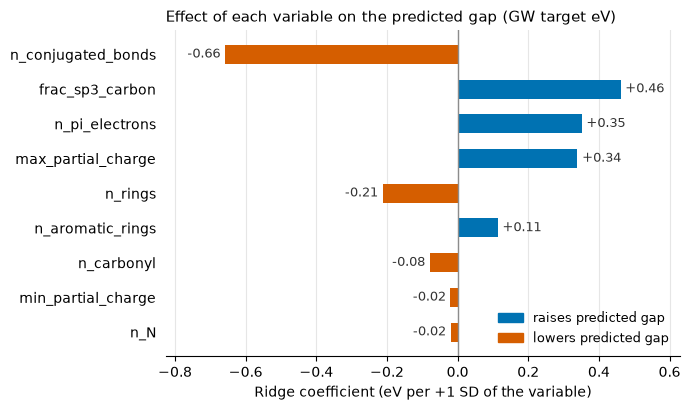

In [ ]:

# Visualization of 
UP, DOWN = "#0072B2", "#D55E00"   # blue = raises the gap, vermillion = lowers it (colour-blind safe)

def plot_ridge_coefficients(coef, path=None):
    coef = coef.reindex(coef.abs().sort_values().index)        # largest |coefficient| at the top
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.barh(coef.index, coef.values, height=0.55, color=np.where(coef >= 0, UP, DOWN))
    ax.axvline(0, color="#8c8c8c", lw=1)                       # baseline: coefficient = 0
    pad = 0.02 * coef.abs().max()
    for y, v in enumerate(coef.values):                        # value at the bar tip
        ax.text(v + (pad if v >= 0 else -pad), y, f"{v:+.2f}", va="center",
                ha="left" if v >= 0 else "right", fontsize=9, color="#333333")
    ax.set_xlabel("Ridge coefficient (eV per +1 SD of the variable)")
    ax.set_title("Effect of each variable on the predicted gap (GW target eV)", loc="left", fontsize=11)
    ax.margins(x=0.15)
    ax.grid(axis="x", color="#e6e6e6", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.tick_params(left=False)
    ax.legend(handles=[Patch(color=UP, label="raises predicted gap"),
                       Patch(color=DOWN, label="lowers predicted gap")],
              frameon=False, loc="lower right", fontsize=9)
    fig.tight_layout()
    if path is not None:
        fig.savefig(path, dpi=300, bbox_inches="tight")
    return fig

plot_ridge_coefficients(coef_A, RESULTS_DIR / "ridge_coefficients_A.png")
plt.show()

### Save Results

In [8]:
# %% Cell 10 --------------------------------------------------------------------------
# 10 save results
pd.DataFrame({"qm9_index": molecules["index"].iloc[test_pos].to_numpy(), "gap_dft_eV": y_test,
              **{f"pred_{k}_eV": main[k]["pred"] for k in "ABC"}}).to_csv(
    RESULTS_DIR / "test_predictions.csv", index=False)
scores.to_csv(RESULTS_DIR / "test_scores.csv")
curve.to_csv(RESULTS_DIR / "learning_curves.csv", index=False)
direction.to_csv(RESULTS_DIR / "shap_directions.csv")
mean_abs.to_csv(RESULTS_DIR / "shap_mean_abs.csv", header=["mean |SHAP| (eV)"])
rho.round(3).to_csv(RESULTS_DIR / "correlation_train.csv")
notice(f"Done. Results in {RESULTS_DIR}")

[  1 min 27.6 s] Done. Results in results/gap_gw


### Presentation Extrapolation

In [9]:
#prediction of aspirin using SMILE
aspirin = Chem.MolFromSmiles("CC(=O)Oc1ccccc1C(=O)O")

# Chemical properties of aspirin 
x_chem = pd.DataFrame([chem_vars(aspirin)])[features].astype(float)


vocab = fp_vocab(train_pos)
fp = morgan.GetSparseCountFingerprint(aspirin).GetNonzeroElements()
x_fp = pd.DataFrame([[fp.get(s, 0) for s in vocab]],
                    columns=[f"fp_{s}" for s in vocab], dtype=np.float32)

x = {"A": x_chem, "B": x_fp, "C": pd.concat([x_chem, x_fp], axis=1)}
for k in "ABC":
    print(MODEL_NAMES[k], f"{main[k]['model'].predict(x[k])[0]:.3f} eV")

covered = sum(s in set(vocab) for s in fp)
print(f"aspirin substructures in vocabulary: {covered}/{len(fp)}")
print(pd.DataFrame({"train_max": main_inputs["A"].max(), "aspirin": x_chem.iloc[0]}))

A: chemistry variables 9.200 eV
B: Morgan counts 8.998 eV
C: combined 8.795 eV
aspirin substructures in vocabulary: 11/25
                    train_max    aspirin
n_conjugated_bonds  10.000000  12.000000
n_aromatic_rings     2.000000   1.000000
frac_sp3_carbon      1.000000   0.111111
n_pi_electrons      16.000000  10.000000
n_carbonyl           4.000000   2.000000
n_N                  7.000000   0.000000
n_rings              9.000000   1.000000
max_partial_charge   0.592146   0.339004
min_partial_charge  -0.031143  -0.477540


In [10]:
# molecules which are treated the same by the models based on their variables.
XA = main_inputs["C"]
XA.drop(columns=["max_partial_charge", "min_partial_charge"]) # partial charge binning effect
group = XA.round(6).groupby(list(XA.columns), dropna=False).ngroup()   # one id per unique row
shared = group.map(group.value_counts()) > 1                            # True if another molecule has the same row
floor = np.mean(np.abs(y - pd.Series(y).groupby(group.to_numpy()).transform("mean").to_numpy()))
print(f"{shared.mean():.1%} share their row; best possible MAE with these inputs = {floor:.3f} eV")

0.2% share their row; best possible MAE with these inputs = 0.000 eV
